# Notebook 6 – Outlier Treatment

# 1. What is an Outlier?


## Step 1 – Understand Concept

An outlier is a data point that is unusually far from most other observations in a dataset.

Outliers may occur because of:
- Data-entry mistakes
- Measurement errors
- Unusual real-world events
- Natural variation in the data
- Special customers or business transactions

Outliers can affect the mean, standard deviation, visualizations, and some Machine Learning algorithms.

However, an outlier is not automatically an error. We must investigate its meaning before deciding whether to remove, cap, transform, or retain it.


## Step 2 – Demonstrate Concept

Consider these monthly charges:

20, 25, 30, 35, 40, 300

Most values are between 20 and 40, but 300 is much higher.

The value 300 may be an outlier.

Possible explanations:
- A typing error: the actual charge was 30.0.
- A valid extreme observation: a customer purchased several additional services.

The correct treatment depends on the actual business meaning.


## Step 3 – Implement the Concept

Charges:
0     20
1     25
2     30
3     35
4     40
5    300
dtype: int64

Mean: 75.0
Median: 32.5


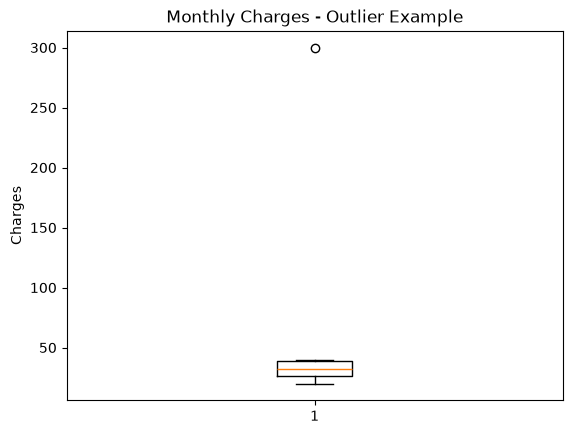

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

charges = pd.Series([20, 25, 30, 35, 40, 300])

print("Charges:")
print(charges)

print("\nMean:", charges.mean())
print("Median:", charges.median())

plt.boxplot(charges)
plt.title("Monthly Charges - Outlier Example")
plt.ylabel("Charges")
plt.show()

## Result / Observation

The value 300 is much higher than the other observations and may be an outlier.

The mean is affected more strongly by this large value than the median.

The box plot helps visualize the unusual value, but neither the mean nor the box plot can tell us whether the value is an error.

We must investigate the record before choosing a treatment.

# 2. Outlier vs Error


## Step 1 – Understand Concept

An outlier is an unusually high or low observation.

An error is a value that is incorrect because of a mistake, system problem, or invalid measurement.

An outlier can be a valid observation, and an error may or may not be detected by an outlier detection method.

Examples:
- Salary = 5,000,000: possibly a valid high salary.
- Age = 250: likely a data-entry error.
- MonthlyCharges = 99999: possibly an extra-zero typing mistake.
- MonthlyCharges = 300: potentially valid for a customer with additional services.

We should use domain knowledge and source records to investigate unusual values.



## Step 2 – Demonstrate Concept

Consider the following records:

| Customer | MonthlyCharges | Possible interpretation |
|---|---:|---|
| C101 | 75 | Typical value |
| C102 | 82 | Typical value |
| C103 | 9999 | Possible data-entry error |
| C104 | 250 | Possible valid premium service |

The value 9999 may be an error if the billing system confirms that it should be 99.99.

The value 250 may be legitimate if the customer has a premium package.

We should not treat both values in the same way without investigating them.


## Step 3 – Implement the Concept


In [2]:
df = pd.DataFrame({
    "Customer": ["C101", "C102", "C103", "C104"],
    "MonthlyCharges": [75, 82, 9999, 250]
})

# Use a threshold only to flag unusual values for investigation.
df["Needs_Investigation"] = df["MonthlyCharges"] > 200

print(df)

  Customer  MonthlyCharges  Needs_Investigation
0     C101              75                False
1     C102              82                False
2     C103            9999                 True
3     C104             250                 True


## Result / Observation

C103 and C104 are flagged because their charges exceed the illustrative threshold of 200.

This does not prove that either value is incorrect.

The threshold is only an initial screening rule. We need business context, billing records, and source verification before deciding how to handle each observation.

# 3. IQR Method


## Step 1 – Understand Concept

The Interquartile Range (IQR) method identifies potential outliers using the middle 50% of numerical data.

Q1 = 25th percentile

Q3 = 75th percentile

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Values below the lower bound or above the upper bound are flagged as potential outliers.

The IQR method is less sensitive to extreme values than the mean and standard deviation.

However, a value outside the bounds is not automatically invalid.



## Step 2 – Demonstrate Concept

Consider the values:

10, 12, 14, 15, 16, 18, 20, 100

The value 100 is much higher than the other observations.

The IQR method calculates the middle spread of the data and establishes lower and upper bounds.

If 100 falls above the upper bound, it is flagged for investigation.

We must still determine whether 100 is an error or a valid extreme observation.



## Step 3 – Implement the Concept

In [3]:
df = pd.DataFrame({
    "Value": [10, 12, 14, 15, 16, 18, 20, 100]
})

Q1 = df["Value"].quantile(0.25)
Q3 = df["Value"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df["Potential_Outlier"] = (
    (df["Value"] < lower_bound)
    | (df["Value"] > upper_bound)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nOutlier detection:")
print(df)

Q1: 13.5
Q3: 18.5
IQR: 5.0
Lower bound: 6.0
Upper bound: 26.0

Outlier detection:
   Value  Potential_Outlier
0     10              False
1     12              False
2     14              False
3     15              False
4     16              False
5     18              False
6     20              False
7    100               True


## Result / Observation

The IQR method calculates a lower and upper bound from the data.

Any value outside these bounds is flagged as a potential outlier.

The method does not tell us whether a value is an error, so we must investigate flagged records before deciding whether to remove, cap, transform, or retain them.

# 4. Z-Score Method


## Step 1 – Understand Concept

The Z-score method measures how far a value is from the mean in units of standard deviation.

A Z-score near zero means the value is close to the mean.

A large positive Z-score indicates a value far above the mean.

A large negative Z-score indicates a value far below the mean.

A common screening rule flags values with an absolute Z-score greater than 3.

This is a guideline, not a universal rule. It works best when the distribution and assumptions make the mean and standard deviation meaningful. It may be unreliable for strongly skewed data or small datasets.


## Step 2 – Demonstrate Concept

Suppose most monthly charges are close to the average.

A customer with a charge several standard deviations above the mean may receive a high Z-score.

We can flag that customer for investigation.

However, if the charges are strongly skewed or contain genuine premium customers, the Z-score method may flag valid observations too.



##  Step 3 – Implement the Concept

In [4]:
df = pd.DataFrame({
    "MonthlyCharges": [45, 48, 50, 52, 49, 51, 47, 200]
})

mean_value = df["MonthlyCharges"].mean()
std_value = df["MonthlyCharges"].std(ddof=0)

if std_value == 0:
    df["Z_Score"] = 0.0
else:
    df["Z_Score"] = (
        (df["MonthlyCharges"] - mean_value) / std_value
    )

df["Potential_Outlier"] = df["Z_Score"].abs() > 3

print(df)

   MonthlyCharges   Z_Score  Potential_Outlier
0              45 -0.454733              False
1              48 -0.394768              False
2              50 -0.354792              False
3              52 -0.314815              False
4              49 -0.374780              False
5              51 -0.334803              False
6              47 -0.414756              False
7             200  2.643447              False


## Result / Observation

The Z-score shows how far each charge is from the mean relative to the standard deviation.

Values with an absolute Z-score greater than 3 are flagged by this rule.

If no observations cross the threshold, that does not prove that the dataset has no outliers. Other methods, such as IQR or domain-specific limits, may be more appropriate.

# 5. Percentile Method


## Step 1 – Understand Concept

The percentile method identifies unusually low or high values using selected percentiles.

For example:
- The 1st percentile represents a low-end threshold.
- The 99th percentile represents a high-end threshold.

Values below the 1st percentile or above the 99th percentile may be flagged.

This method is useful when we want to focus on the extreme tails of a distribution.

However, percentile thresholds depend on the dataset and business context. They do not prove that the flagged observations are incorrect.



## Step 2 – Demonstrate Concept

Suppose we analyze customer spending.

We choose the 5th and 95th percentiles as illustrative thresholds.

Values below the 5th percentile or above the 95th percentile are flagged for review.

This can help identify unusually low or high spending without assuming that every flagged value is an error.



## Step 3 – Implement the Concept

In [5]:
df = pd.DataFrame({
    "Spending": [
        100, 120, 130, 140, 150, 160,
        170, 180, 190, 200, 220, 1000
    ]
})

lower_bound = df["Spending"].quantile(0.05)
upper_bound = df["Spending"].quantile(0.95)

df["Potential_Outlier"] = (
    (df["Spending"] < lower_bound)
    | (df["Spending"] > upper_bound)
)

print("5th percentile:", lower_bound)
print("95th percentile:", upper_bound)
print(df)

5th percentile: 111.0
95th percentile: 570.9999999999994
    Spending  Potential_Outlier
0        100               True
1        120              False
2        130              False
3        140              False
4        150              False
5        160              False
6        170              False
7        180              False
8        190              False
9        200              False
10       220              False
11      1000               True


## Result / Observation

The percentile method flags values outside the selected percentile range.

The thresholds are configurable and should be chosen according to the distribution and purpose of the analysis.

A high spending value could be a genuine customer purchase, so we should investigate it before changing the data.

# 6. Winsorization


## Step 1 – Understand Concept

Winsorization reduces the influence of extreme values by replacing values beyond selected percentile limits with the corresponding boundary values.

For example, with 5th and 95th percentile limits:
- Values below the 5th percentile are replaced by the 5th percentile value.
- Values above the 95th percentile are replaced by the 95th percentile value.

Winsorization retains the number of rows while reducing the influence of extreme observations.

It can be useful when extreme values are valid but overly influential.

It should not be used to hide data-entry errors that should instead be corrected from reliable source information.


## Step 2 – Demonstrate Concept

Suppose the values are:

10, 12, 14, 15, 16, 18, 100

If we set an upper limit of 20 for this example, the value 100 becomes 20.

The row is retained, but its numerical value is limited.

In practice, percentile limits should be calculated from appropriate training data when preparing a predictive ML model.



## Step 3 – Implement the Concept

In [6]:
df = pd.DataFrame({
    "Value": [10, 12, 14, 15, 16, 18, 100]
})

lower_limit = df["Value"].quantile(0.05)
upper_limit = df["Value"].quantile(0.95)

df["Winsorized_Value"] = df["Value"].clip(
    lower=lower_limit,
    upper=upper_limit
)

print(df)

   Value  Winsorized_Value
0     10              10.6
1     12              12.0
2     14              14.0
3     15              15.0
4     16              16.0
5     18              18.0
6    100              75.4


## Result / Observation

Values below or above the chosen percentile limits are replaced with the corresponding limits.

The dataset keeps the same number of rows, but its extreme values are less influential.

The selected limits should be documented, and winsorization should only be applied when it makes sense for the data and business problem.

# 7. Capping


## Step 1 – Understand Concept

Capping replaces values that exceed a specified upper or lower limit with the chosen boundary.

For example:
- Values greater than 100 are replaced with 100.
- Values less than 0 are replaced with 0.

Capping can reduce the effect of extreme values without deleting records.

It is appropriate only when the limits are justified by domain knowledge or a documented statistical rule.

If a value is an obvious data-entry error, correcting it from the original source is usually preferable to capping it.


## Step 2 – Demonstrate Concept

Suppose the valid business range for a particular score is 0 to 100.

Observed scores:

45, 60, 75, 110

If the business confirms that scores cannot exceed 100, the value 110 violates the rule and should be investigated.

If the value cannot be corrected from the source and the chosen policy allows capping, it may be capped at 100.

Do not assume that every numerical column has a natural maximum of 100.



## Step 3 – Implement the Concept

In [7]:
df = pd.DataFrame({
    "Score": [45, 60, 75, 110, -5]
})

lower_limit = 0
upper_limit = 100

df["Capped_Score"] = df["Score"].clip(
    lower=lower_limit,
    upper=upper_limit
)

print(df)

   Score  Capped_Score
0     45            45
1     60            60
2     75            75
3    110           100
4     -5             0


## Result / Observation

The value 110 is capped at 100, and -5 is capped at 0.

The original values are preserved in the Score column so that the changes can be reviewed.

In a real workflow, first investigate whether the values are errors. Use capping only when the chosen boundaries are appropriate and the treatment is documented.

# 8. Flooring


## Step 1 – Understand Concept

Flooring is a lower-bound treatment in which values below a selected minimum are replaced with that minimum.

For example, if a valid business score cannot be below 0, a value of -5 may be floored to 0 after investigation.

Flooring can reduce the influence of unusually low values.

However, negative values may be meaningful in some datasets, such as profit, temperature, or financial returns. Therefore, the lower bound must be justified by the meaning of the feature.



## Step 2 – Demonstrate Concept

Consider product ratings that are required to range from 1 to 5.

Observed values:

-2, 2, 3, 4, 5

The value -2 violates the permitted range.

If the source confirms that the rating must be between 1 and 5 and the data cannot be corrected, a documented flooring policy may replace -2 with 1.

However, if the rating was entered incorrectly, source correction is preferable.



## Step 3 – Implement the Concept

In [8]:
df = pd.DataFrame({
    "Rating": [-2, 2, 3, 4, 5]
})

minimum_allowed = 1

df["Floored_Rating"] = df["Rating"].clip(
    lower=minimum_allowed
)

print(df)

   Rating  Floored_Rating
0      -2               1
1       2               2
2       3               3
3       4               4
4       5               5


## Result / Observation

The value -2 is replaced with 1, while values already above the minimum remain unchanged.

Flooring should only be used when the lower boundary is justified.

In this example, the rating scale also has a maximum of 5, so any value above 5 would need separate investigation and handling.

# 9. Transformation


## Step 1 – Understand Concept

Transformation changes the scale or mathematical representation of a feature.

A log transformation is commonly used to reduce right skewness and make large values less dominant.

Other transformations include:
- Square root transformation
- Power transformations
- Yeo-Johnson transformation

Transformation does not necessarily remove an outlier. It changes how values are represented.

A genuine extreme value may still be important after transformation.

Log transformation requires positive values unless an appropriate adjustment or alternative method is used.



## Step 2 – Demonstrate Concept

Suppose customer spending values are:

100, 120, 150, 200, 5000

The value 5000 is much larger than the others.

A logarithmic transformation compresses the scale of large values, making differences between extreme values less pronounced.

This can help some models handle strongly skewed numerical features.

We should compare the distribution before and after transformation and confirm that the transformed values remain suitable for the intended analysis.



## Step 3 – Implement the Concept

   Spending  Log_Transformed
0       100         4.615121
1       120         4.795791
2       150         5.017280
3       200         5.303305
4      5000         8.517393


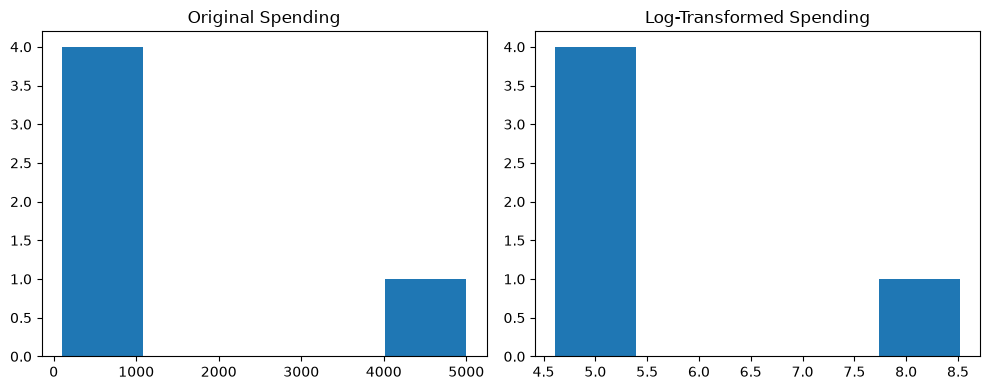

In [9]:
df = pd.DataFrame({
    "Spending": [100, 120, 150, 200, 5000]
})

# All values are positive, so log1p is suitable here.
df["Log_Transformed"] = np.log1p(df["Spending"])

print(df)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(df["Spending"], bins=5)
axes[0].set_title("Original Spending")

axes[1].hist(df["Log_Transformed"], bins=5)
axes[1].set_title("Log-Transformed Spending")

plt.tight_layout()
plt.show()

## Result / Observation

The log transformation compresses the scale of larger spending values.

It may reduce right skewness, but it does not prove that the largest value is an error or remove the observation.

Before choosing a transformation, check the distribution, the feature's meaning, the model requirements, and whether the transformation is suitable for the data.

# 10. Removing Outliers


## Step 1 – Understand Concept

Removing outliers means excluding selected observations from a dataset.

Removal may be appropriate when:
- A value is confirmed to be an error and cannot be corrected.
- A record violates a required business constraint.
- A measurement is invalid or corrupted.
- A clearly documented analysis rule requires exclusion.

Removal may be dangerous when:
- The observation is valid.
- Rare events are important.
- High-value customers or unusual transactions are meaningful.
- The removed data represents a group that the model must learn about.

We should document the reason for removing each record.



## Step 2 – Demonstrate Concept

Consider ages:

25, 28, 30, 32, 250

The age 250 is implausible for a normal human employee record and may be a data-entry error.

First, check the original record.

If the correct age can be recovered, fix it.

If the value is confirmed to be invalid but cannot be corrected, exclusion may be appropriate.

Do not use the same decision for a valid extreme value, such as a high customer bill.



## Step 3 – Implement the Concept

In [10]:
df = pd.DataFrame({
    "Employee": ["Arun", "Priya", "Kumar", "Meena"],
    "Age": [25, 28, 30, 250]
})

# Illustrative screening rule for this example.
# A flagged record must be investigated before removal.
df["Needs_Investigation"] = ~df["Age"].between(0, 120)

print("Original data:")
print(df)

# Demonstration only:
# Assume the source has confirmed that the age 250 is invalid
# and that it cannot be corrected.
clean_df = df[~df["Needs_Investigation"]].copy()

print("\nAfter excluding the confirmed invalid record:")
print(clean_df)

Original data:
  Employee  Age  Needs_Investigation
0     Arun   25                False
1    Priya   28                False
2    Kumar   30                False
3    Meena  250                 True

After excluding the confirmed invalid record:
  Employee  Age  Needs_Investigation
0     Arun   25                False
1    Priya   28                False
2    Kumar   30                False


## Result / Observation

The age 250 is flagged because it violates the illustrative age range.

The example excludes it only under the stated assumption that the source has confirmed the value is invalid and it cannot be corrected.

In a real preprocessing task, do not remove a record solely because a statistical method flags it. Investigate the record and document the decision first.

# 11. Retaining Outliers


## Step 1 – Understand Concept

Retaining an outlier means keeping the observation because it is valid and important.

An extreme observation may represent:
- A premium customer
- A major transaction
- A rare but real event
- An important business case
- A genuine high or low measurement

Removing valid extremes may cause the dataset to lose important information.

If a valid outlier affects model performance, we can evaluate whether transformation, robust scaling, or an outlier-resistant model is appropriate. Retention does not mean ignoring its impact.



## Step 2 – Demonstrate Concept

Suppose customer charges are:

50, 55, 60, 65, 300

The value 300 is unusually high.

After checking the billing system, we confirm that the customer has a legitimate premium package.

Therefore, 300 is a valid extreme observation and should generally be retained.

We can compare model performance with suitable preprocessing choices, but we should not delete the value merely to make the distribution look more normal.


## Step 3 – Implement the Concept

In [11]:
df = pd.DataFrame({
    "CustomerID": ["C101", "C102", "C103", "C104", "C105"],
    "MonthlyCharges": [50, 55, 60, 65, 300],
    "Plan": ["Basic", "Basic", "Standard", "Standard", "Premium"]
})

Q1 = df["MonthlyCharges"].quantile(0.25)
Q3 = df["MonthlyCharges"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

df["Potential_Outlier"] = (
    df["MonthlyCharges"] > upper_bound
)

print(df)

# Assume the billing records confirm that every charge is valid.
retained_df = df.copy()

print("\nValid observations retained:")
print(retained_df)

  CustomerID  MonthlyCharges      Plan  Potential_Outlier
0       C101              50     Basic              False
1       C102              55     Basic              False
2       C103              60  Standard              False
3       C104              65  Standard              False
4       C105             300   Premium               True

Valid observations retained:
  CustomerID  MonthlyCharges      Plan  Potential_Outlier
0       C101              50     Basic              False
1       C102              55     Basic              False
2       C103              60  Standard              False
3       C104              65  Standard              False
4       C105             300   Premium               True


## Result / Observation

The unusually high charge is flagged for investigation.

Assuming the billing records confirm that it is valid, the observation is retained.

The premium customer may represent an important business segment. Removing this customer could reduce the model's ability to learn about high-value customers.

# 12. Outlier Investigation and Treatment Decision


## Step 1 – Understand Concept

After detecting an outlier, we should investigate it before selecting a treatment.

For every detected outlier, answer these questions:

1. Is it a data-entry or measurement error?
2. Is it a valid extreme observation?
3. Should it be removed?
4. Should it be capped or floored?
5. Should it be transformed?
6. Why is the selected treatment appropriate?

Possible decisions:

- Correct: use when the correct value can be verified.
- Remove: use for confirmed invalid observations that cannot be corrected, when exclusion is justified.
- Cap or floor: use when justified limits reduce the unwanted influence of extreme values.
- Transform: use when a suitable transformation addresses skewness or scale issues.
- Retain: use when the observation is valid and important.

No statistical detection method can make every treatment decision automatically.



## Step 2 – Demonstrate Concept

Consider three observations:

| Feature | Observed value | Investigation | Possible decision |
|---|---:|---|---|
| Employee age | 250 | Confirmed typing error; correct value unavailable | Exclude if justified |
| Customer charge | 300 | Verified premium subscription | Retain |
| Customer spending | 5000 | Verified purchase; distribution strongly right-skewed | Consider transformation |

These decisions differ because the business meaning of each observation differs.

The same numerical value can require different treatment in different datasets.


## Step 3 – Implement the Concept

In [12]:
df = pd.DataFrame({
    "RecordID": ["R101", "R102", "R103"],
    "Feature": ["Age", "MonthlyCharges", "Spending"],
    "Value": [250, 300, 5000],
    "Investigation": [
        "Confirmed invalid; cannot be corrected",
        "Verified premium subscription",
        "Verified purchase; strongly right-skewed feature"
    ],
    "Decision": [
        "Exclude if justified",
        "Retain",
        "Consider transformation"
    ],
    "Reason": [
        "Implausible age confirmed by source investigation",
        "Valid business observation",
        "Transformation may reduce skewness"
    ]
})

print(df)

  RecordID         Feature  Value  \
0     R101             Age    250   
1     R102  MonthlyCharges    300   
2     R103        Spending   5000   

                                      Investigation                 Decision  \
0            Confirmed invalid; cannot be corrected     Exclude if justified   
1                     Verified premium subscription                   Retain   
2  Verified purchase; strongly right-skewed feature  Consider transformation   

                                              Reason  
0  Implausible age confirmed by source investigation  
1                         Valid business observation  
2                 Transformation may reduce skewness  


## Result / Observation

The decision table documents why each observation receives a different treatment.

In a real project, the investigation should use the original source records, business rules, and domain knowledge.

The decision and its reason should be recorded so another person can review and understand the preprocessing choice.

# Final Summary – Outlier Treatment

In this notebook, we learned:

1. What is an Outlier?
2. Outlier vs Error
3. IQR Method
4. Z-Score Method
5. Percentile Method
6. Winsorization
7. Capping
8. Flooring
9. Transformation
10. Removing Outliers
11. Retaining Outliers
12. Outlier Investigation and Treatment Decision

## Important Decision Rule

For every detected outlier:

- Investigate whether it is an error.
- Check whether it is a valid extreme observation.
- Decide whether correction, removal, capping, flooring, transformation, or retention is appropriate.
- Explain why the selected treatment makes sense.
- Document the decision and validate the data afterward.

## Final Workflow

Detect → Investigate → Verify → Choose Treatment → Implement → Compare Before and After → Validate

Outlier treatment should improve data quality and model suitability without unnecessarily removing meaningful information.